# 43. Flow Matching calibration head from checkpoint 002.24

**Research question:** does a deterministic, sensor-conditioned SE(3) × ℝ *correction velocity field* improve calibration updates compared with the existing single-step regression head?

This notebook is deliberately a **small, clean baseline**, derived from notebook 42. It keeps KAIST splits, 5-second windows, the pretrained pooled-transformer architecture, calibration conventions and ordinary **true-calibration + prior-perturbation** augmentation, but omits notebook 42's topology-mixing, extra views, common-frame equivariance and signed-pair objectives.

- **Regression control:** checkpoint `kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt` (read-only).
- **FM initialization:** copy transformer, pooler and shared MLP weights only; initialize the velocity head randomly, with zero initial weights on correction-state and time inputs.
- **Primary training:** freeze the pretrained backbone; supervise analytical conditional velocities, **without integrating / differentiating through the ODE**.
- **Correction convention:** `[φx,φy,φz,ρx,ρy,ρz,Δτ]` (rotation first), `T_new = Exp(Δξ) @ T_current`. The flow starts at the identity correction, not a random sampled pose.
- **Model selection:** analytical velocity loss on validation data. **Step-count selection:** *validation* only. **Final comparison:** paired held-out test windows, with geometric residual rotation / translation and absolute clock offset errors.
- **Performance:** record actual device, parameter counts and **measured per-window latency**. Values are produced when you execute the notebook in your repository; no scores or timings are pre-filled.

**Requirements:** installed package with `flow_matching/`, updated `PooledCalibrationFlowModel`, config appendix and original dataset utilities. The KAIST dataset, pose CSV files and checkpoint must exist on your machine. Run cells sequentially. No extra generic diffusion noise or noise-level predictor is used.

## 1. Imports and repository root

In [1]:
from pathlib import Path
from dataclasses import asdict
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository (with src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import (CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig)
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__, "CUDA available:", torch.cuda.is_available())

Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126 CUDA available: True


## 2. Reproducible settings and checkpoint 002.24

In [2]:
RUN_NAME = "kaist_pooled_calibration_fm_head"
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology"
SOURCE_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED = 23456
VAL_AUG_SEED = 34567
TEST_AUG_SEED = 45678
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE = 16
NUM_WORKERS = 0

# Conservative starting point: frozen 002.24 backbone + fresh FM head.
HEAD_ONLY_EPOCHS = 100
JOINT_FINE_TUNE_EPOCHS = 0  # Optional subsequent stage; default experiment is head-only.
HEAD_LEARNING_RATE = 5e-4
BACKBONE_LEARNING_RATE = 5e-6
LR_REDUCE_STEPS = 5
LR_REDUCE_FACTOR = 0.5
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
MAX_TRAIN_BATCHES_PER_EPOCH = None  # Set e.g. 80 to iterate quickly.
MAX_VAL_BATCHES_PER_EPOCH = None
RUN_TRAINING = True

FM_INTEGRATION_STEPS = 8
FM_INTEGRATION_METHOD = "midpoint"
ABLATION_STEPS = (1, 2, 4, 8, 16, 32)
ABLATION_METHODS = ("euler", "midpoint")
VAL_ABLATION_WINDOWS_PER_SEQUENCE = 12
TEST_WINDOWS_PER_SEQUENCE = 50
TIMING_WINDOWS = 24
TIMING_WARMUP = 5
TIMING_REPEATS = 3

# Same simple physical augmentation strengths as notebook 42.
PRIOR_ROTATION_MAX_RAD = np.deg2rad(60.0)
PRIOR_ROTATION_SCALE_RAD = np.deg2rad(30.0)
PRIOR_TIME_OFFSET_MAX_S = 0.500
PRIOR_TIME_OFFSET_SCALE_S = 0.250
TRUE_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_TIME_OFFSET_MAX_S = 0.030

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

if not SOURCE_CHECKPOINT.is_file():
    raise FileNotFoundError(f"002.24 checkpoint not found: {SOURCE_CHECKPOINT}")
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, "| Run:", RUN_NAME)
print("Source weights:", SOURCE_CHECKPOINT)
print("Prior corruption: 0–60° truncated Student-t, one calibration per physical window")
print("True-calibration augmentation: rotations ≤180°, clock offsets ≤30 ms; no translation")
print("FM loss: analytic velocity MSE, no ODE backpropagation")

Device: cuda | Run: kaist_pooled_calibration_fm_head
Source weights: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
Prior corruption: 0–60° truncated Student-t, one calibration per physical window
True-calibration augmentation: rotations ≤180°, clock offsets ≤30 ms; no translation
FM loss: analytic velocity MSE, no ODE backpropagation


## 3. KAIST train / validation / held-out test (from notebook 42)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

train 2006 windows
validation 418 windows
test 699 windows


## 4. Only two standard augmentations: true calibration, then prior perturbation

No synthetic IMU, sensor replacement, common-body rotation, opposite-prior view, or measurement noise is used. This preserves notebook 42's **single-sensor Student-t prior** and physically consistent true-calibration modification, but removes all multi-view machinery. The ground truth is captured *before* perturbing the current prior.

In [4]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=PRIOR_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_ROTATION_SCALE_RAD, degrees_of_freedom=3),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=PRIOR_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TIME_OFFSET_SCALE_S, degrees_of_freedom=3),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
true_calibration_augmenter = AugmentationPipeline(true_calibration_config)
prior_perturber = CalibrationPriorPerturber(prior_config)

def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)

def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

def augment_window(base_window: WindowBatch, generator: torch.Generator) -> WindowBatch:
    physical_truth_window = true_calibration_augmenter(base_window, generator=generator).augmented_window
    true_states = physical_truth_window.current_calibration
    _, sampled_xi, sampled_tau = prior_perturber(true_states, generator=generator)
    noisy_states = apply_prior_perturbation(true_states, sampled_xi, sampled_tau)
    return clone_with_current_calibration(physical_truth_window, noisy_states)

def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Augmented window must contain calibration truth targets.")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Incomplete target for {key!r}.")
        # Rotation-first, LEFT-applied correction: T_true = Exp(delta) @ T_prior.
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau

print("True calibration augmentation:", true_calibration_config.true_calibration)
print("Prior perturbation:", prior_config)

True calibration augmentation: TrueCalibrationAugmentationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=3.141592653589793, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=None, time_offset=PerturbationMagnitudeConfig(maximum=0.03, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3))
Prior perturbation: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.5235987755982988, degrees_of_freedom=3), translation=None, time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.25, degrees_

## 5. Restore regression checkpoint, copy the backbone, initialize fresh FM head

In [5]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=True,
)

regression_model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_CHECKPOINT, model=regression_model, map_location=DEVICE, restore_rng_state=False)
regression_model.eval()
regression_model.requires_grad_(False)

fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
fm_model.initialize_backbone_from_regression(regression_model, freeze=flow_config.freeze_backbone_initially)
fm_loss_weights = flow_config.loss.to_loss_weights()

# Initial state/time columns are zero; feature-dependent weights are NEW random weights.
first_linear = next(layer for layer in fm_model.head.net if isinstance(layer, nn.Linear))
assert torch.count_nonzero(first_linear.weight[:, fm_model.head.condition_dim:]).item() == 0
for component in ("transformer_encoder", "pooler", "mlp_body"):
    source_parameters = getattr(regression_model, component).state_dict()
    fm_parameters = getattr(fm_model, component).state_dict()
    assert source_parameters.keys() == fm_parameters.keys()
    assert all(torch.equal(source_parameters[key], fm_parameters[key]) for key in source_parameters)

def count_parameters(model):
    return sum(param.numel() for param in model.parameters())

def count_trainable(model):
    return sum(param.numel() for param in model.parameters() if param.requires_grad)

parameter_report = pd.DataFrame([
    {"model": "002.24 regression", "total_parameters": count_parameters(regression_model), "trainable_now": count_trainable(regression_model), "head_parameters": count_parameters(regression_model.head)},
    {"model": "43 Flow Matching", "total_parameters": count_parameters(fm_model), "trainable_now": count_trainable(fm_model), "head_parameters": count_parameters(fm_model.head)},
])
display(parameter_report)
print("FM backbone frozen:", fm_model.feature_extractor_frozen, "| velocity head starts without state/time dependence.")

,model,total_parameters,trainable_now,head_parameters
0,002.24 regression,2554505,0,25353
1,43 Flow Matching,2555399,26247,26247


FM backbone frozen: True | velocity head starts without state/time dependence.


## 6. Reuse the existing WindowStep preprocessing for FM training

`WindowStep` owns the geometry-processing and tokenization logic. Rather than duplicating those unpublished interfaces or running the regression head, a tiny temporary adapter captures the **actual** `TokenBatch` passed to the model and exits before the updater. The training path then calls `fm_model.forward_flow_matching(tokens, ...)` directly. Any earlier exception from geometry/tokenization is re-raised, not swallowed.

In [6]:
class _TokensCaptured(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.captured_tokens = None
        self.captured_context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.captured_tokens = tokens
        self.captured_context = calibration_context
        raise _TokensCaptured()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)
capture_model = _TokenCaptureModel()
capture_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=capture_model, calibration_updater=calibration_updater)

def tokenize_window(window: WindowBatch):
    capture_model.captured_tokens = None
    capture_model.captured_context = None
    try:
        capture_step(window)
    except _TokensCaptured:
        pass
    if capture_model.captured_tokens is None:
        raise RuntimeError("WindowStep did not call model; check the pipeline/tokenizer contract.")
    return capture_model.captured_tokens, capture_model.captured_context

def get_model_output(model: nn.Module, tokens: TokenBatch, calibration_context=None, *, steps=None, method=None):
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, calibration_context, num_steps=steps, method=method)
    return model(tokens, calibration_context)

if DEVICE.type == "cuda": torch.cuda.empty_cache()
# One check of the physical augmentation and token routing, before training.
smoke_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
smoke_window = augment_window(smoke_base, augmentation_generator(TRAIN_AUG_SEED))
smoke_tokens, smoke_context = tokenize_window(smoke_window)
smoke_xi, smoke_tau = correction_targets(smoke_window)
assert tuple(smoke_tokens.calibration_keys) == tuple(smoke_window.current_calibration)
assert all(smoke_xi[k].shape == (len(smoke_tokens.x), 6) and smoke_tau[k].shape == (len(smoke_tokens.x), 1) for k in smoke_tokens.calibration_keys)
with torch.no_grad():
    smoke_output = fm_model.forward_flow_matching(smoke_tokens, smoke_xi, smoke_tau, calibration_context=smoke_context)
assert smoke_output.predicted_velocity.shape == (len(smoke_tokens.x), len(smoke_tokens.calibration_keys), 7)
assert torch.allclose(smoke_output.flow_batch.target_velocity[..., :6], torch.stack([smoke_xi[k] for k in smoke_tokens.calibration_keys], 1))
print("Tokenization and analytic FM supervision smoke test: PASS", tuple(smoke_tokens.x.shape), tuple(smoke_output.predicted_velocity.shape))

Tokenization and analytic FM supervision smoke test: PASS (16, 1098, 8) (16, 3, 7)


## 7. Analytic FM objective (no integration in the training graph)

In [7]:
def flow_supervision(window: WindowBatch, *, generator: torch.Generator):
    tokens, context = tokenize_window(window)
    delta_xi, delta_tau = correction_targets(window)
    output = fm_model.forward_flow_matching(tokens, delta_xi, delta_tau, calibration_context=context, generator=generator)
    losses = calibration_velocity_loss(output.predicted_velocity, output.flow_batch.target_velocity, weights=fm_loss_weights)
    return losses, output

@torch.no_grad()
def validate_constant_velocity_identity():
    # If v is constant, all integration step counts represent the same correction.
    fm_model.eval()
    tokens, context = tokenize_window(smoke_window)
    original = get_model_output(fm_model, tokens, context, steps=1, method="midpoint")
    many = get_model_output(fm_model, tokens, context, steps=8, method="midpoint")
    max_difference = max((original.predictions[k].delta_xi - many.predictions[k].delta_xi).abs().max().item() for k in tokens.calibration_keys)
    print(f"Initial 1-vs-8 midpoint step difference: {max_difference:.3e}")
    assert max_difference < 1e-3, "Check FM head state/time initialization and Lie-group integration."

validate_constant_velocity_identity()

Initial 1-vs-8 midpoint step difference: 5.960e-08


## 8. Train/evaluate epochs with one augmented view per physical window

In [8]:
optimizer = torch.optim.AdamW(fm_model.head.parameters(), lr=HEAD_LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)

def run_fm_epoch(loader, *, training: bool, seed: int, max_batches=None):
    fm_model.train(training)
    aug_generator = augmentation_generator(seed)
    losses_by_component = defaultdict(float)
    examples = 0
    start = time.perf_counter()
    grad_context = torch.enable_grad() if training else torch.no_grad()
    with grad_context:
        for batch_index, original_batch in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break
            base = window_batch_to(original_batch, DEVICE, dtype=DTYPE)
            augmented = augment_window(base, aug_generator)
            if training:
                optimizer.zero_grad(set_to_none=True)
            loss, _ = flow_supervision(augmented, generator=aug_generator)
            if training:
                loss.total.backward()
                torch.nn.utils.clip_grad_norm_([p for p in fm_model.parameters() if p.requires_grad], GRADIENT_CLIP_NORM)
                optimizer.step()
            batch_size = len(next(iter(augmented.current_calibration.values())).transform)
            values = loss.detached_metrics()
            for key, value in values.items():
                # Active COUNT is summed directly; averaged loss values are weighted by windows.
                losses_by_component[key] += value if key == "fm_active_rotation_count" else value * batch_size
            examples += batch_size
    if examples == 0:
        raise RuntimeError("No batches were processed.")
    summary = {key: (value if key == "fm_active_rotation_count" else value / examples) for key, value in losses_by_component.items()}
    summary["num_windows"] = examples
    summary["epoch_seconds"] = time.perf_counter() - start
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return summary

# Minimal gradient verification, uses exact analytic path, not the integrated output.
fm_model.train()
optimizer.zero_grad(set_to_none=True)
smoke_loss, _ = flow_supervision(smoke_window, generator=augmentation_generator(TRAIN_AUG_SEED + 99))
smoke_loss.total.backward()
assert any(p.grad is not None and torch.isfinite(p.grad).all() for p in fm_model.head.parameters())
assert all(p.grad is None for component in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in component.parameters())
optimizer.zero_grad(set_to_none=True)
print("Frozen-backbone FM gradient smoke test: PASS")

Frozen-backbone FM gradient smoke test: PASS


In [9]:

# Resume the FM experiment from the last completed epoch.
RESUME_FROM_LAST = True

start_epoch = 0
global_step = 0
best_validation_loss = float("inf")
history = []

if RESUME_FROM_LAST:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)

    # Restore model weights, optimizer moments, scheduler state and RNG.
    load_training_checkpoint(
        LAST_CHECKPOINT_PATH,
        model=fm_model,
        optimizer=optimizer,
        scheduler=scheduler,
        map_location=DEVICE,
        restore_rng_state=True,
    )

    # Read epoch counters and previous best validation loss.
    # Only load trusted checkpoints produced by your own code.
    checkpoint = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)

    start_epoch = int(checkpoint["epoch"])
    global_step = int(checkpoint["global_step"])
    best_validation_loss = float(checkpoint["extra_state"]["best_validation_loss"])

    history_path = RUN_DIR / "fm_learning_history.csv"
    if history_path.is_file():
        history = pd.read_csv(history_path).to_dict("records")
        history = [row for row in history if int(row["epoch"]) <= start_epoch]

    # The current checkpoint is from the head-only training stage.
    if len(optimizer.param_groups) != 1:
        raise RuntimeError("Expected a head-only optimizer with one parameter group.")

    fm_model.freeze_feature_extractor(True)

    print(f"Resuming after completed epoch {start_epoch}")
    print(f"Global step: {global_step}")
    print(f"Best validation loss: {best_validation_loss:.6f}")
    print(f"Restored head learning rate: {optimizer.param_groups[0]['lr']:.3e}")
    print(f"Historical metric rows: {len(history)}")


Resuming after completed epoch 51
Global step: 6375
Best validation loss: 0.339951
Restored head learning rate: 2.500e-04
Historical metric rows: 0


## 9. Checkpoint selection, training, and learning curves

Validation uses a fixed augmentation seed on each epoch, so the criterion compares the **same types of windows and faults**, not a new random target every time. Only analytic FM velocity loss selects the best checkpoint. This is intentionally different from the endpoint regression loss of 002.24.

In [10]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [11]:
experiment_metadata = {
    "run_name": RUN_NAME,
    "source_checkpoint": str(SOURCE_CHECKPOINT),
    "source_architecture": "PooledCalibrationModel",
    "trained_architecture": "PooledCalibrationFlowModel",
    "backbone_config": model_config,
    "flow_config": flow_config,
    "true_calibration_config": true_calibration_config,
    "prior_config": prior_config,
    "data_splits": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "training_loss": "analytic_conditional_lie_velocity_mse_only",
    "initialization": "002.24_pretrained_backbone_fresh_random_fm_head_zero_state_time_input_columns",
}

if RUN_TRAINING:
    total_epochs = HEAD_ONLY_EPOCHS + JOINT_FINE_TUNE_EPOCHS
    for epoch in range(start_epoch, total_epochs):
        if epoch == HEAD_ONLY_EPOCHS and JOINT_FINE_TUNE_EPOCHS > 0:
            fm_model.freeze_feature_extractor(False)
            backbone_params = [p for component in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in component.parameters()]
            optimizer.add_param_group({"params": backbone_params, "lr": BACKBONE_LEARNING_RATE})
            print("Unlocked pretrained backbone for optional low-LR fine-tuning.")

        train_metrics = run_fm_epoch(train_loader, training=True, seed=TRAIN_AUG_SEED + epoch, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        validation_metrics = run_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED, max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        global_step += math.ceil(train_metrics["num_windows"] / BATCH_SIZE)
        val_loss = validation_metrics["loss_fm_total"]
        scheduler.step(val_loss)
        row = {"epoch": epoch + 1, "phase": "head-only" if epoch < HEAD_ONLY_EPOCHS else "joint", "head_lr": optimizer.param_groups[0]["lr"], **{f"train/{k}": v for k, v in train_metrics.items()}, **{f"val/{k}": v for k, v in validation_metrics.items()}}
        history.append(row)
        if val_loss < best_validation_loss:
            best_validation_loss = val_loss
            save_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch + 1, global_step=global_step, metrics=validation_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
            label = " [BEST]"
        else:
            label = ""
        save_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch + 1, global_step=global_step, metrics=validation_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
        print(f"epoch {epoch+1:3d}/{total_epochs} | train velocity loss={train_metrics['loss_fm_total']:.4f} | val velocity loss={val_loss:.4f} | head LR={optimizer.param_groups[0]['lr']:.2e} | {label}", flush=True)
        pd.DataFrame(history).to_csv(RUN_DIR / "fm_learning_history.csv", index=False)
else:
    print("RUN_TRAINING=False: will load a previously saved FM best checkpoint.")

if not BEST_CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"FM best checkpoint does not exist: {BEST_CHECKPOINT_PATH}")
load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.eval()
regression_model.eval()
print("FM selected checkpoint:", BEST_CHECKPOINT_PATH, "| best analytic velocity loss:", best_validation_loss if history else "see checkpoint")

epoch  52/100 | train velocity loss=0.5462 | val velocity loss=0.3893 | head LR=2.50e-04 | 
epoch  53/100 | train velocity loss=0.4927 | val velocity loss=0.3600 | head LR=2.50e-04 | 
epoch  54/100 | train velocity loss=0.4640 | val velocity loss=0.3228 | head LR=2.50e-04 |  [BEST]
epoch  55/100 | train velocity loss=0.4770 | val velocity loss=0.4140 | head LR=2.50e-04 | 
epoch  56/100 | train velocity loss=0.5282 | val velocity loss=0.3418 | head LR=2.50e-04 | 
epoch  57/100 | train velocity loss=0.5388 | val velocity loss=0.3343 | head LR=2.50e-04 | 
epoch  58/100 | train velocity loss=0.4427 | val velocity loss=0.3595 | head LR=2.50e-04 | 
epoch  59/100 | train velocity loss=0.4803 | val velocity loss=0.3815 | head LR=2.50e-04 | 
epoch  60/100 | train velocity loss=0.5228 | val velocity loss=0.3294 | head LR=1.25e-04 | 
epoch  61/100 | train velocity loss=0.5717 | val velocity loss=0.3470 | head LR=1.25e-04 | 
epoch  62/100 | train velocity loss=0.4913 | val velocity loss=0.3207 | h

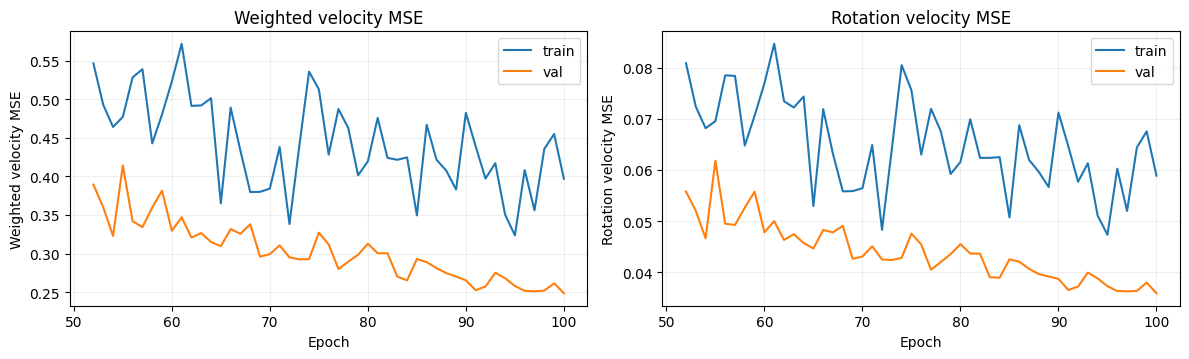

In [12]:
if history:
    hdf = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
    for col, label in (("loss_fm_total", "Weighted velocity MSE"), ("loss_fm_rotation", "Rotation velocity MSE")):
        ax = axes[0] if col == "loss_fm_total" else axes[1]
        for split in ("train", "val"):
            ax.plot(hdf["epoch"], hdf[f"{split}/{col}"], label=split)
        ax.set(xlabel="Epoch", ylabel=label, title=label)
        ax.grid(alpha=0.2); ax.legend()
    fig.tight_layout(); plt.show()

## 10. Build deterministic, paired evaluation cases

All predictions below operate on the **same tokenized window, prior calibration and ground truth**. The validation cases are used exclusively for selecting integration steps. The held-out test cases are used only for the final comparison. Cache prepared cases once to avoid timing/data-order artifacts.

In [13]:
def sampled_indices_by_sequence(dataset, names, per_sequence: int):
    result = []
    for sequence in names:
        indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=int)
        if not len(indices):
            continue
        positions = np.unique(np.linspace(0, len(indices) - 1, min(per_sequence, len(indices))).round().astype(int))
        result.extend([(sequence, int(indices[p])) for p in positions])
    if not result:
        raise RuntimeError("No windows found for evaluation.")
    return result

@torch.no_grad()
def prepare_evaluation_cases(dataset, sequences, windows_per_sequence: int, seed: int):
    cases = []
    generator = augmentation_generator(seed)
    for sequence, index in sampled_indices_by_sequence(dataset, sequences, windows_per_sequence):
        window = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
        augmented = augment_window(window, generator)
        tokens, context = tokenize_window(augmented)
        xi, tau = correction_targets(augmented)
        cases.append({"sequence": sequence, "index": index, "window": augmented, "tokens": tokens, "context": context, "target_xi": xi, "target_tau": tau})
    return cases

validation_cases = prepare_evaluation_cases(val_dataset, VAL_NAMES, VAL_ABLATION_WINDOWS_PER_SEQUENCE, VAL_AUG_SEED + 900)
print("Fixed validation cases for ODE-step ablation:", len(validation_cases))

Fixed validation cases for ODE-step ablation: 24


## 11. Final-pose metrics with geometric residuals

Compute `Exp(delta_pred) @ T_prior` and compare with target `T_true` in the *actual extrinsic state*. Do not equate raw Lie-algebra coordinate MSE with geometric rotation/translation error. For each calibration key, record initial error, residual error and resulting improvement.

In [14]:
@torch.no_grad()
def correction_metrics(case, prediction, key):
    state = case["window"].current_calibration[key]
    truth = case["window"].targets[key]
    current_T = state.transform
    target_T = truth.next_transform
    predicted_T = se3_exp(prediction.delta_xi) @ current_T
    initial_residual = se3_log(target_T @ torch.linalg.inv(current_T))[:, :3]
    final_residual = se3_log(target_T @ torch.linalg.inv(predicted_T))[:, :3]
    initial_rotation_deg = torch.rad2deg(torch.linalg.vector_norm(initial_residual, dim=-1))
    final_rotation_deg = torch.rad2deg(torch.linalg.vector_norm(final_residual, dim=-1))
    initial_translation_cm = 100 * torch.linalg.vector_norm(current_T[:, :3, 3] - target_T[:, :3, 3], dim=-1)
    final_translation_cm = 100 * torch.linalg.vector_norm(predicted_T[:, :3, 3] - target_T[:, :3, 3], dim=-1)
    initial_tau_ms = 1000 * torch.abs(state.time_offset - truth.next_time_offset).reshape(-1)
    final_tau_ms = 1000 * torch.abs(state.time_offset + prediction.delta_tau - truth.next_time_offset).reshape(-1)
    return {"initial_rotation_deg": initial_rotation_deg, "rotation_error_deg": final_rotation_deg,
            "initial_translation_cm": initial_translation_cm, "translation_error_cm": final_translation_cm,
            "initial_tau_ms": initial_tau_ms, "tau_error_ms": final_tau_ms}

@torch.no_grad()
def evaluate_cases(model, cases, model_label, *, steps=None, method=None):
    model.eval()
    rows = []
    for case in cases:
        output = get_model_output(model, case["tokens"], case["context"], steps=steps, method=method)
        for key, pred in output.predictions.items():
            metrics = correction_metrics(case, pred, key)
            for i in range(len(pred.delta_xi)):
                row = {"model": model_label, "sequence": case["sequence"], "index": case["index"], "key": key}
                row["is_active_fault"] = bool(torch.linalg.vector_norm(case["target_xi"][key][i, :3]).item() > 1e-5 or abs(case["target_tau"][key][i, 0].item()) > 1e-6)
                row.update({metric: float(value[i].item()) for metric, value in metrics.items()})
                row["rotation_gain_deg"] = row["initial_rotation_deg"] - row["rotation_error_deg"]
                rows.append(row)
    return pd.DataFrame(rows)

## 12. Validate Euler/midpoint × integration steps, select once

The choice of integration resolution is made **only on the validation split**. The table includes rotation/translation/clock residuals and nominal number of field evaluations (NFE). The source regressor always uses one model pass. The chosen solver is then held fixed for the test comparison.

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


,method,steps,NFE,rotation_mean_deg,rotation_p90_deg,translation_mean_cm,tau_mean_ms
0,euler,1,1,6.298,11.258,17.751,23.273
1,euler,2,2,6.258,11.024,17.686,21.548
6,midpoint,1,2,6.244,10.883,17.649,20.012
2,euler,4,4,6.205,10.786,17.516,20.617
7,midpoint,2,4,6.171,10.843,17.353,19.664
3,euler,8,8,6.170,10.797,17.373,20.116
8,midpoint,4,8,6.143,10.841,17.217,19.602
4,euler,16,16,6.151,10.812,17.279,19.860
9,midpoint,8,16,6.135,10.848,17.177,19.599
5,euler,32,32,6.142,10.830,17.225,19.731


Selected FM integration: midpoint, 32 steps, 64 velocity-network evaluations


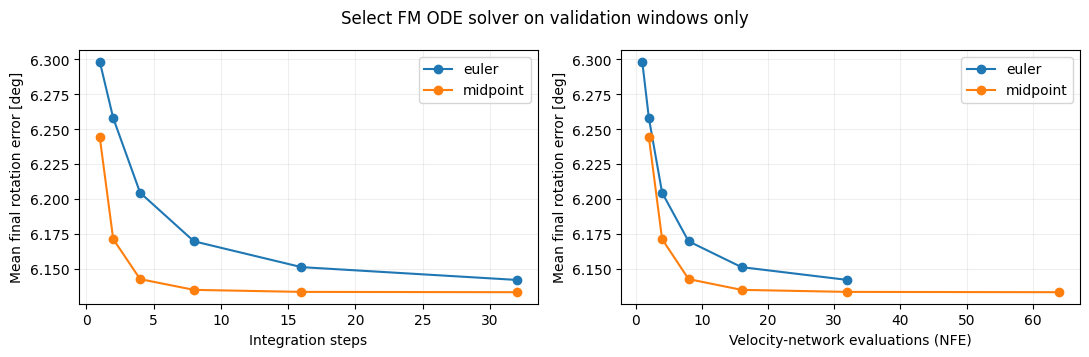

In [15]:
ablation_records = []
for method in ABLATION_METHODS:
    for steps in ABLATION_STEPS:
        values = evaluate_cases(fm_model, validation_cases, "FM", steps=steps, method=method)
        values = values[values.is_active_fault]  # Choose correction fidelity, not healthy-key dominance.
        if values.empty:
            raise RuntimeError("No active calibration faults in validation cases; increase VAL_ABLATION_WINDOWS_PER_SEQUENCE.")
        ablation_records.append({"method": method, "steps": steps, "NFE": steps * (2 if method == "midpoint" else 1),
                                "rotation_mean_deg": values["rotation_error_deg"].mean(),
                                "rotation_p90_deg": values["rotation_error_deg"].quantile(0.9),
                                "translation_mean_cm": values["translation_error_cm"].mean(),
                                "tau_mean_ms": values["tau_error_ms"].mean()})
ablation_df = pd.DataFrame(ablation_records).sort_values(["NFE", "method"])
display(ablation_df.round(3))
ablation_df.to_csv(RUN_DIR / "fm_validation_integration_step_ablation.csv", index=False)

# Choose by rotation error, then fewer NFE. This is a *validation* choice, not a test-set selection.
selected = ablation_df.sort_values(["rotation_mean_deg", "NFE"]).iloc[0]
SELECTED_STEPS = int(selected["steps"])
SELECTED_METHOD = str(selected["method"])
print(f"Selected FM integration: {SELECTED_METHOD}, {SELECTED_STEPS} steps, {int(selected['NFE'])} velocity-network evaluations")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for method, table in ablation_df.groupby("method"):
    table = table.sort_values("steps")
    axes[0].plot(table["steps"], table["rotation_mean_deg"], "-o", label=method)
    axes[1].plot(table["NFE"], table["rotation_mean_deg"], "-o", label=method)
for ax, xlabel in zip(axes, ("Integration steps", "Velocity-network evaluations (NFE)")):
    ax.set(xlabel=xlabel, ylabel="Mean final rotation error [deg]")
    ax.grid(alpha=0.2); ax.legend()
fig.suptitle("Select FM ODE solver on validation windows only")
fig.tight_layout(); plt.show()

## 13. Held-out paired evaluation: checkpoint 002.24 versus FM

Report after training, on independent test sequences with identical samples for both models. A table of **absolute residuals** is more informative than comparing FM velocity loss with regression training loss.

In [16]:
test_cases = prepare_evaluation_cases(test_dataset, TEST_NAMES, TEST_WINDOWS_PER_SEQUENCE, TEST_AUG_SEED + 900)
print("Fixed held-out windows:", len(test_cases))
with torch.inference_mode():
    baseline_test = evaluate_cases(regression_model, test_cases, "002.24 regression")
    fm_test = evaluate_cases(fm_model, test_cases, "FM 43", steps=SELECTED_STEPS, method=SELECTED_METHOD)
test_results = pd.concat((baseline_test, fm_test), ignore_index=True)
test_results.to_csv(RUN_DIR / "fm_vs_00224_paired_test_errors.csv", index=False)

summary_columns = ["initial_rotation_deg", "rotation_error_deg", "rotation_gain_deg", "translation_error_cm", "tau_error_ms"]
summary = test_results.groupby("model")[summary_columns].agg(["mean", "median"])
print("Held-out evaluation. All numbers are measured after executing this notebook.")
display(summary.round(3))
print("ACTIVE FAULTS ONLY (important: prevents healthy calibrations from hiding failure to correct the injected fault):")
display(test_results[test_results.is_active_fault].groupby("model")[["initial_rotation_deg", "rotation_error_deg", "rotation_gain_deg", "translation_error_cm", "tau_error_ms"]].agg(["mean", "median"]).round(3))
print("HEALTHY CALIBRATIONS ONLY (should remain close to zero correction):")
display(test_results[~test_results.is_active_fault].groupby("model")[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]].mean().round(3))
print("Per calibration key (including healthy keys):")
display(test_results.groupby(["model", "key"])[["rotation_error_deg", "translation_error_cm", "tau_error_ms", "rotation_gain_deg"]].mean().round(3))

# Every row must have its counterpart in the other model: no independent test resampling.
paired_keys = ["sequence", "index", "key"]
source_rows = baseline_test.set_index(paired_keys).sort_index()
flow_rows = fm_test.set_index(paired_keys).sort_index()
assert source_rows.index.equals(flow_rows.index)
paired_difference = flow_rows[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]] - source_rows[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]]
print("Paired FM minus regression (negative is better):")
display(paired_difference.agg(["mean", "median"]).round(3))

Fixed held-out windows: 100
Held-out evaluation. All numbers are measured after executing this notebook.


initial_rotation_deg        rotation_error_deg         \
                                  mean median               mean median   
model                                                                     
002.24 regression                6.448    0.0              1.875  0.138   
FM 43                            6.448    0.0              2.113  0.459   

                  rotation_gain_deg        translation_error_cm         \
                               mean median                 mean median   
model                                                                    
002.24 regression             4.573 -0.067                4.762  0.340   
FM 43                         4.335 -0.246                5.469  1.242   

                  tau_error_ms         
                          mean median  
model                                  
002.24 regression        5.289  1.042  
FM 43                    5.776  1.393

ACTIVE FAULTS ONLY (important: prevents healthy calibrations from hiding failure to correct the injected fault):


initial_rotation_deg         rotation_error_deg         \
                                  mean  median               mean median   
model                                                                      
002.24 regression               19.344  15.088              5.251  4.453   
FM 43                           19.344  15.088              5.459  4.348   

                  rotation_gain_deg         translation_error_cm          \
                               mean  median                 mean  median   
model                                                                      
002.24 regression            14.092  10.847               13.421  10.100   
FM 43                        13.885  11.096               14.231  11.323   

                  tau_error_ms          
                          mean  median  
model                                   
002.24 regression       13.520  10.816  
FM 43                   14.487  10.075

HEALTHY CALIBRATIONS ONLY (should remain close to zero correction):


,rotation_error_deg,translation_error_cm,tau_error_ms
model,,,
002.24 regression,0.186,0.433,1.174
FM 43,0.440,1.088,1.421


Per calibration key (including healthy keys):


rotation_error_deg  translation_error_cm  \
model             key                                                     
002.24 regression imu                       1.573                 2.030   
                  lidar                     2.251                 6.539   
                  lidar_right               1.799                 5.717   
FM 43             imu                       1.827                 3.172   
                  lidar                     2.479                 6.809   
                  lidar_right               2.032                 6.427   

                               tau_error_ms  rotation_gain_deg  
model             key                                           
002.24 regression imu                 3.133              4.874  
                  lidar               6.266              5.402  
                  lidar_right         6.469              3.444  
FM 43             imu                 3.706              4.620  
                  lidar               7.325              5.174  
                  lidar_right         6.298              3.212

Paired FM minus regression (negative is better):


,rotation_error_deg,translation_error_cm,tau_error_ms
mean,0.238,0.707,0.487
median,0.206,0.531,0.308


## 14. Performance plots: error distributions, gains, prior-angle bins, time offsets

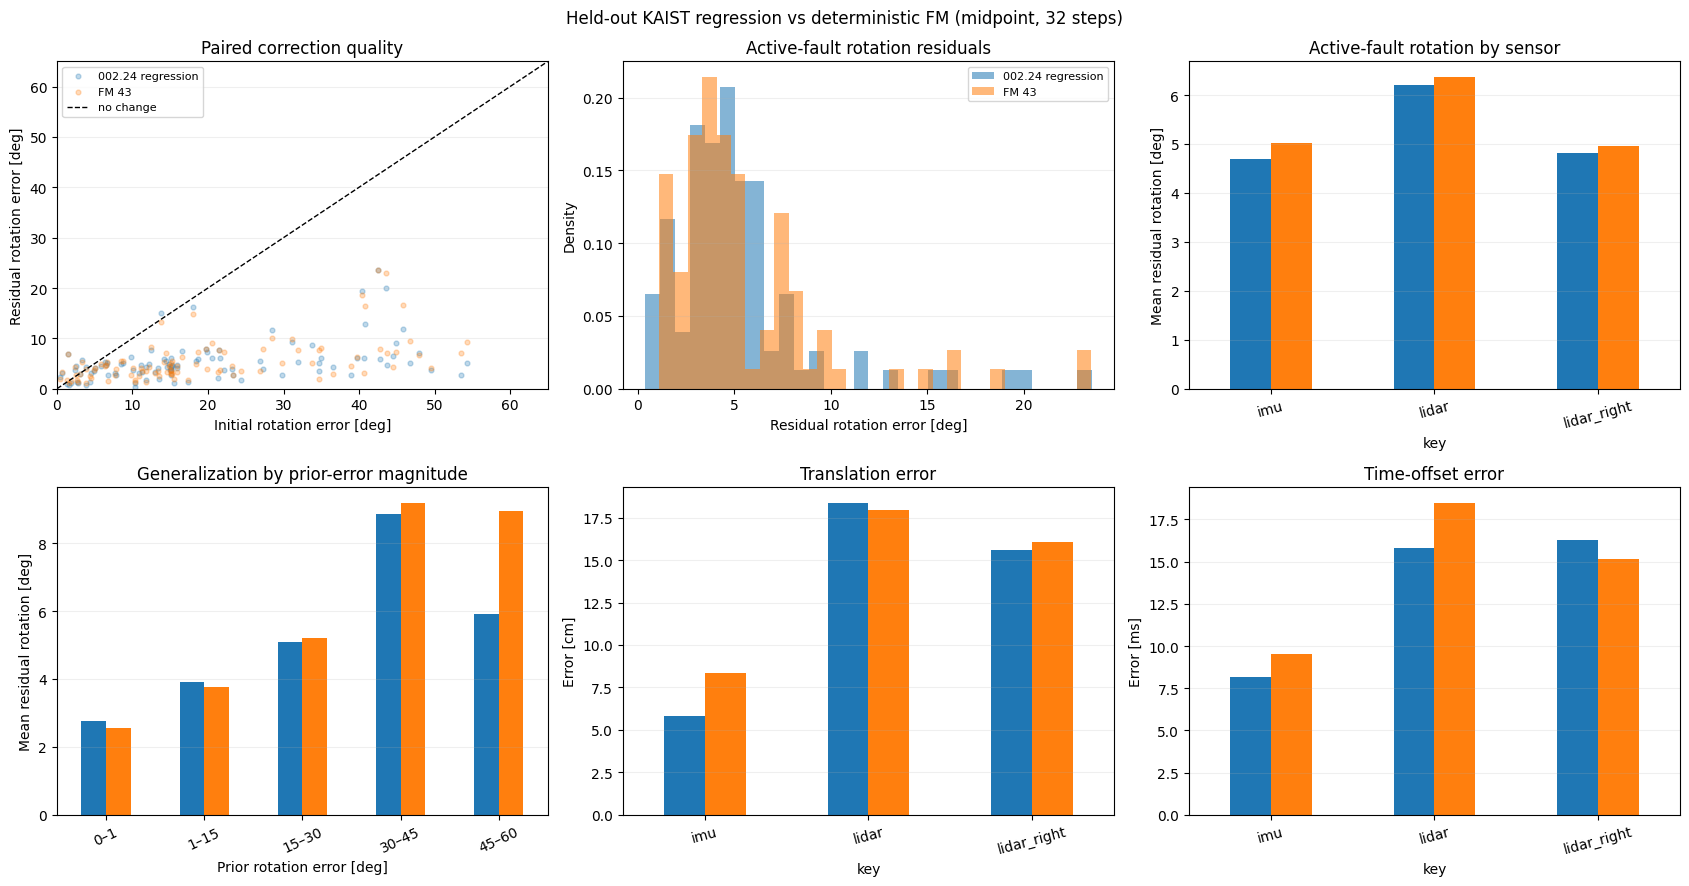

Samples per initial-angle bin:


initial_angle_bin
0–1       2
1–15     44
15–30    30
30–45    18
45–60     6
Name: n, dtype: int64

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
colors = {"002.24 regression": "tab:blue", "FM 43": "tab:orange"}

# 1. Before / after correction for each model.
for model_name, frame in test_results[test_results.is_active_fault].groupby("model"):
    axes[0, 0].scatter(frame["initial_rotation_deg"], frame["rotation_error_deg"], alpha=0.28, s=12, label=model_name, color=colors[model_name])
limit = max(65, float(test_results[["initial_rotation_deg", "rotation_error_deg"]].max().max()) * 1.05)
axes[0, 0].plot([0, limit], [0, limit], "k--", lw=1, label="no change")
axes[0, 0].set(xlabel="Initial rotation error [deg]", ylabel="Residual rotation error [deg]", title="Paired correction quality", xlim=(0, limit), ylim=(0, limit)); axes[0, 0].legend(fontsize=8)

# 2. Rotation error distributions.
for name, data in test_results[test_results.is_active_fault].groupby("model"):
    axes[0, 1].hist(data["rotation_error_deg"], bins=30, alpha=0.55, density=True, color=colors[name], label=name)
axes[0, 1].set(xlabel="Residual rotation error [deg]", ylabel="Density", title="Active-fault rotation residuals"); axes[0, 1].legend(fontsize=8)

# 3. Mean performance by calibration key.
key_means = test_results[test_results.is_active_fault].groupby(["key", "model"])["rotation_error_deg"].mean().unstack("model").reindex(columns=colors.keys())
key_means.plot.bar(ax=axes[0, 2], color=list(colors.values()), rot=15, legend=False)
axes[0, 2].set(ylabel="Mean residual rotation [deg]", title="Active-fault rotation by sensor")

# 4. Error by initial-angle bin. Empty bins remain absent (don't infer missing results).
angle_bins = [-1e-6, 1, 15, 30, 45, 60, 90, 180]
angle_labels = ["0–1", "1–15", "15–30", "30–45", "45–60", "60–90", "90–180"]
plot_df = test_results[test_results.is_active_fault].copy()
plot_df["initial_angle_bin"] = pd.cut(plot_df["initial_rotation_deg"], bins=angle_bins, labels=angle_labels, include_lowest=True)
bins_summary = plot_df.groupby(["initial_angle_bin", "model"], observed=True)["rotation_error_deg"].mean().unstack("model")
bins_summary.plot.bar(ax=axes[1, 0], color=list(colors.values()), rot=25, legend=False)
axes[1, 0].set(xlabel="Prior rotation error [deg]", ylabel="Mean residual rotation [deg]", title="Generalization by prior-error magnitude")

# 5. Translation and 6. clock errors.
for ax, metric, ylabel, title in ((axes[1, 1], "translation_error_cm", "Error [cm]", "Translation error"), (axes[1, 2], "tau_error_ms", "Error [ms]", "Time-offset error")):
    values = test_results[test_results.is_active_fault].groupby(["key", "model"])[metric].mean().unstack("model").reindex(columns=colors.keys())
    values.plot.bar(ax=ax, color=list(colors.values()), rot=15, legend=False)
    ax.set(ylabel=ylabel, title=title)

for ax in axes.flat:
    ax.grid(alpha=0.2, axis="y")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle(f"Held-out KAIST regression vs deterministic FM ({SELECTED_METHOD}, {SELECTED_STEPS} steps)")
fig.tight_layout(); plt.show()
fig.savefig(RUN_DIR / "fm_vs_00224_test_plots.png", dpi=160, bbox_inches="tight")

print("Samples per initial-angle bin:")
display(plot_df[plot_df["model"] == "FM 43"].groupby("initial_angle_bin", observed=True).size().rename("n"))

## 15. Parameter count and measured milliseconds per window

**Model-only:** fixed already-tokenized **batch size 1**, `eval()` and `torch.inference_mode()`. **Full window:** `WindowStep` preprocessing, model execution and calibration updater on the *same fixed augmented WindowBatch*. Both use the chosen FM solver. CUDA is synchronized around timing; warmups are excluded. Neither metric includes disk loading or augmentation. Absolute latency depends on hardware and token counts.

In [18]:
def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

@torch.inference_mode()
def benchmark_callable(fn, *, warmup=TIMING_WARMUP, repeats=TIMING_REPEATS):
    for _ in range(warmup):
        fn()
    synchronize_device()
    readings = []
    for _ in range(repeats):
        synchronize_device()
        start = time.perf_counter()
        fn()
        synchronize_device()
        readings.append(1000 * (time.perf_counter() - start))
    return float(np.median(readings))

regression_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=regression_model, calibration_updater=calibration_updater)
flow_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=fm_model, calibration_updater=calibration_updater)
# Keep the already validated, selected numerical solver for real-world inference.
fm_model.integration_steps = SELECTED_STEPS
fm_model.integration_method = SELECTED_METHOD

regression_model.eval(); fm_model.eval()
bench_cases = test_cases[:min(TIMING_WINDOWS, len(test_cases))]
latency_records = []
for model_label, model, step in (("002.24 regression", regression_model, regression_step), ("FM 43", fm_model, flow_step)):
    times_model, times_pipeline = [], []
    for case in bench_cases:
        times_model.append(benchmark_callable(lambda c=case, m=model: get_model_output(m, c["tokens"], c["context"], steps=SELECTED_STEPS, method=SELECTED_METHOD)))
        times_pipeline.append(benchmark_callable(lambda c=case, s=step: s(c["window"])))
    latency_records.append({"model": model_label, "parameters_total": count_parameters(model), "parameters_trainable_at_evaluation": count_trainable(model), "parameters_prediction_head": count_parameters(model.head),
                            "model_only_median_ms_per_window": float(np.median(times_model)), "model_only_p90_ms_per_window": float(np.quantile(times_model, 0.9)),
                            "full_window_median_ms_per_window": float(np.median(times_pipeline)), "full_window_p90_ms_per_window": float(np.quantile(times_pipeline, 0.9)),
                            "timed_windows": len(times_model), "device": str(DEVICE),
                            "velocity_network_evaluations": 1 if model_label == "002.24 regression" else SELECTED_STEPS * (2 if SELECTED_METHOD == "midpoint" else 1)})
latency_df = pd.DataFrame(latency_records)
latency_df.to_csv(RUN_DIR / "fm_vs_00224_window_timing.csv", index=False)
print(f"Measured on {DEVICE}, {len(bench_cases)} common B=1 windows, median of {TIMING_REPEATS} timed runs after {TIMING_WARMUP} warmups each:")
display(latency_df.round(3))
for row in latency_records:
    print(f"{row['model']}: {row['parameters_total']:,} total params ({row['parameters_prediction_head']:,} in head); "
          f"model-only {row['model_only_median_ms_per_window']:.2f} ms/window; full WindowStep {row['full_window_median_ms_per_window']:.2f} ms/window; "
          f"model evaluations={row['velocity_network_evaluations']}")

Measured on cuda, 24 common B=1 windows, median of 3 timed runs after 5 warmups each:


,model,parameters_total,parameters_trainable_at_evaluation,parameters_prediction_head,model_only_median_ms_per_window,model_only_p90_ms_per_window,full_window_median_ms_per_window,full_window_p90_ms_per_window,timed_windows,device,velocity_network_evaluations
0,002.24 regression,2554505,0,25353,21.035,28.054,39.548,47.795,24,cuda,1
1,FM 43,2555399,26247,26247,346.471,399.381,367.921,406.922,24,cuda,64


002.24 regression: 2,554,505 total params (25,353 in head); model-only 21.03 ms/window; full WindowStep 39.55 ms/window; model evaluations=1
FM 43: 2,555,399 total params (26,247 in head); model-only 346.47 ms/window; full WindowStep 367.92 ms/window; model evaluations=64


## 16. Summary and reproducibility checklist

These printed numbers are populated **only after training on your data**. The step-count sweep uses validation data; the final error and latency report uses held-out test data. No claim about large-angle improvement beyond the 0–60° training distribution should be made from this first experiment.

In [19]:
print("=" * 84)
print("EXPERIMENT 43: FROZEN PRETRAINED BACKBONE + ANALYTIC LIE FLOW MATCHING")
print("=" * 84)
print("Source regression checkpoint:", SOURCE_CHECKPOINT)
print("Trained FM best checkpoint:", BEST_CHECKPOINT_PATH)
print("Training: 0–60 degree single-calibration prior faults; true extrinsic rotations up to 180 degrees")
print("FM training: direct velocity MSE; no ODE in loss; initialization from zero correction")
print(f"Chosen validation solver: {SELECTED_METHOD}, {SELECTED_STEPS} steps")
print("Test windows:", len(test_cases), "| test pose/key pairs:", len(fm_test))
for model_label in ("002.24 regression", "FM 43"):
    scores = test_results[(test_results.model == model_label) & test_results.is_active_fault]
    latency = latency_df[latency_df.model == model_label].iloc[0]
    print(f"{model_label} [ACTIVE FAULTS]: rotation={scores.rotation_error_deg.mean():.3f} deg, translation={scores.translation_error_cm.mean():.3f} cm, tau={scores.tau_error_ms.mean():.3f} ms; "
          f"parameters={int(latency.parameters_total):,}; model-only={latency.model_only_median_ms_per_window:.3f} ms/window; full={latency.full_window_median_ms_per_window:.3f} ms/window")
print("Artifacts saved under:", RUN_DIR)

EXPERIMENT 43: FROZEN PRETRAINED BACKBONE + ANALYTIC LIE FLOW MATCHING
Source regression checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
Trained FM best checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_head/best.pt
Training: 0–60 degree single-calibration prior faults; true extrinsic rotations up to 180 degrees
FM training: direct velocity MSE; no ODE in loss; initialization from zero correction
Chosen validation solver: midpoint, 32 steps
Test windows: 100 | test pose/key pairs: 300
002.24 regression [ACTIVE FAULTS]: rotation=5.251 deg, translation=13.421 cm, tau=13.520 ms; parameters=2,554,505; model-only=21.035 ms/window; full=39.548 ms/window
FM 43 [ACTIVE FAULTS]: rotation=5.459 deg, translation=14.231 cm, tau=14.487 ms; parameters=2,555,399; model-only=346.471 ms/window; full=367.921 ms/window
Artifacts saved under: /home/camel/Skoltech/

mean   median  count
angle_deg model                                     
0         002.24 regression    1.188    0.946     24
          FM                   1.079    0.875     24
15        002.24 regression    4.530    3.959     24
          FM                   4.615    3.542     24
30        002.24 regression    4.584    4.238     24
          FM                   4.510    4.432     24
45        002.24 regression    5.610    5.107     24
          FM                   5.666    4.673     24
60        002.24 regression    6.560    5.500     24
          FM                   9.479    8.488     24
90        002.24 regression   39.949   33.893     24
          FM                  43.675   40.282     24
120       002.24 regression  112.990  110.748     24
          FM                 112.103  110.663     24
150       002.24 regression  148.600  151.002     24
          FM                 149.644  151.180     24
170       002.24 regression  163.074  168.292     24
          FM                 163.664  168.518     24
179       002.24 regression  163.390  166.805     24
          FM                 164.132  168.715     24

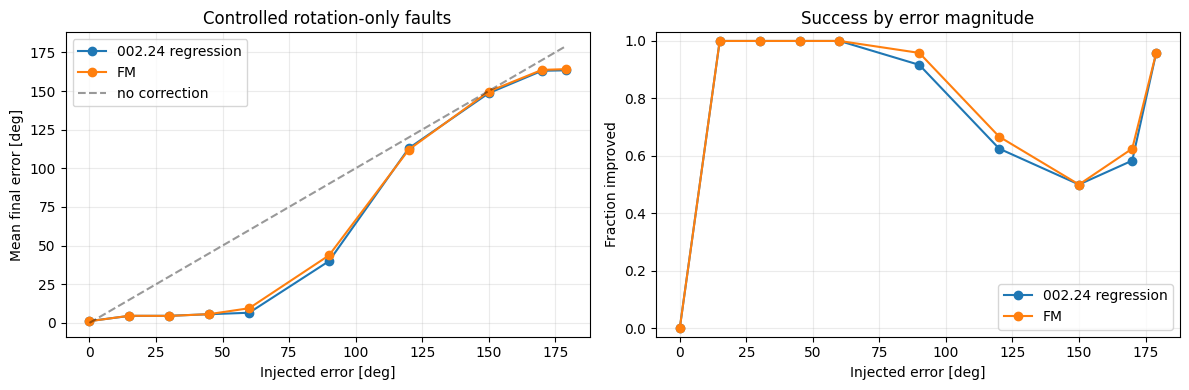

NameError: name 'indices' is not defined

In [20]:
# Standalone notebook-43-compatible controlled angular grid. Place after correction_metrics,
# get_model_output, sampled_indices_by_sequence, and SELECTED_STEPS/SELECTED_METHOD exist.
# No random prior magnitudes: EXACT prescribed errors and uniform random axes, one key at a time.
ANGLE_GRID_DEG = (0, 15, 30, 45, 60, 90, 120, 150, 170, 179)
ANGLE_GRID_SPLIT = "validation"  # Switch to "test" for the final untouched held-out grid only.
ANGLE_GRID_WINDOWS_PER_SEQUENCE = 2
ANGLE_GRID_AXES_PER_WINDOW = 2
ANGLE_GRID_SEED = 58721

@torch.inference_mode()
def evaluate_balanced_angle_grid():
    dataset, sequence_names = (val_dataset, VAL_NAMES) if ANGLE_GRID_SPLIT == "validation" else (test_dataset, TEST_NAMES)
    assert ANGLE_GRID_SPLIT in ("validation", "test")
    axes_generator = augmentation_generator(ANGLE_GRID_SEED)
    rows = []
    fm_model.eval()
    regression_model.eval()
    indices = sampled_indices_by_sequence(dataset, sequence_names, ANGLE_GRID_WINDOWS_PER_SEQUENCE)

    for sequence, index in indices:
        base = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
        physical_truth = true_calibration_augmenter(base, generator=axes_generator).augmented_window
        truth_states = physical_truth.current_calibration
        for active_key in CALIBRATION_KEYS:
            for angle_deg in ANGLE_GRID_DEG:
                for axis_index in range(ANGLE_GRID_AXES_PER_WINDOW):
                    axis = torch.randn((1, 3), dtype=DTYPE, device=DEVICE, generator=axes_generator)
                    axis = axis / axis.norm(dim=-1, keepdim=True).clamp_min(1e-12)
                    delta = {key: torch.zeros((1, 6), dtype=DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
                    delta[active_key][:, :3] = axis * np.deg2rad(angle_deg)
                    tau = {key: torch.zeros((1, 1), dtype=DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
                    prior = apply_prior_perturbation(truth_states, delta, tau)
                    case_window = clone_with_current_calibration(physical_truth, prior)
                    tokens, context = tokenize_window(case_window)
                    case = {"window": case_window}
                    for label, model in (("002.24 regression", regression_model), ("FM", fm_model)):
                        pred = get_model_output(model, tokens, context, steps=SELECTED_STEPS, method=SELECTED_METHOD).predictions[active_key]
                        metrics = correction_metrics(case, pred, active_key)
                        rows.append({"split": ANGLE_GRID_SPLIT, "sequence": sequence, "index": index, "key": active_key,
                                     "angle_deg": angle_deg, "axis_id": axis_index, "model": label,
                                     **{name: float(values[0].item()) for name, values in metrics.items()}})
    return pd.DataFrame(rows), indices

angle_grid_df, indices = evaluate_balanced_angle_grid()
angle_grid_df.to_csv(RUN_DIR / f"fm_balanced_angle_grid_{ANGLE_GRID_SPLIT}.csv", index=False)
angle_grid_mean = angle_grid_df.groupby(["angle_deg", "model"])["rotation_error_deg"].agg(["mean", "median", "count"])
display(angle_grid_mean.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, data in angle_grid_df.groupby("model"):
    mean = data.groupby("angle_deg")["rotation_error_deg"].mean()
    improved = data.assign(improved=data.rotation_error_deg < data.initial_rotation_deg - 1e-3).groupby("angle_deg")["improved"].mean()
    axes[0].plot(mean.index, mean, "-o", label=name)
    axes[1].plot(improved.index, improved, "-o", label=name)
axes[0].plot(ANGLE_GRID_DEG, ANGLE_GRID_DEG, "k--", alpha=.4, label="no correction")
axes[0].set(xlabel="Injected error [deg]", ylabel="Mean final error [deg]", title="Controlled rotation-only faults")
axes[1].set(xlabel="Injected error [deg]", ylabel="Fraction improved", ylim=(-.03, 1.03), title="Success by error magnitude")
for ax in axes:
    ax.legend(); ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(RUN_DIR / f"fm_balanced_angle_grid_{ANGLE_GRID_SPLIT}.png", dpi=160)
plt.show()
print("Each point samples", len(indices), "physical windows x", ANGLE_GRID_AXES_PER_WINDOW, "axes x", len(CALIBRATION_KEYS), "calibration keys.")
